# Step-by-Step Linear Regression Project (with scikit-learn data)

This section demonstrates a complete linear regression workflow using the California Housing dataset from scikit-learn.

We'll cover:
- Loading the dataset
- Data exploration
- Preprocessing (splitting, scaling)
- Model training
- Evaluation
- Visualization
- Saving results

## 1) Setup: imports and dataset load

We'll use scikit-learn's California Housing dataset and common libraries for analysis and visualization. If you run this in a fresh kernel, uncomment the pip-install lines at the top to install missing packages.

In [29]:
%pip install seaborn --quiet
%pip install scikit-learn pandas matplotlib seaborn joblib --quiet
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# load dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dataset loaded — rows:", df.shape[0], "columns:", df.shape[1])

print("dataset loaded -rows:", df.shape[0], "columns", df.shape[1])

# quick look
display(df.head())

# target name
print('Target column:', housing.target.name)

Dataset loaded — rows: 20640 columns: 9
dataset loaded -rows: 20640 columns 9


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Target column: MedHouseVal


## 2) Exploratory Data Analysis (EDA)

We'll inspect distributions, summary statistics, and feature correlations to understand relationships with the target (median house value).

numeric columns summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


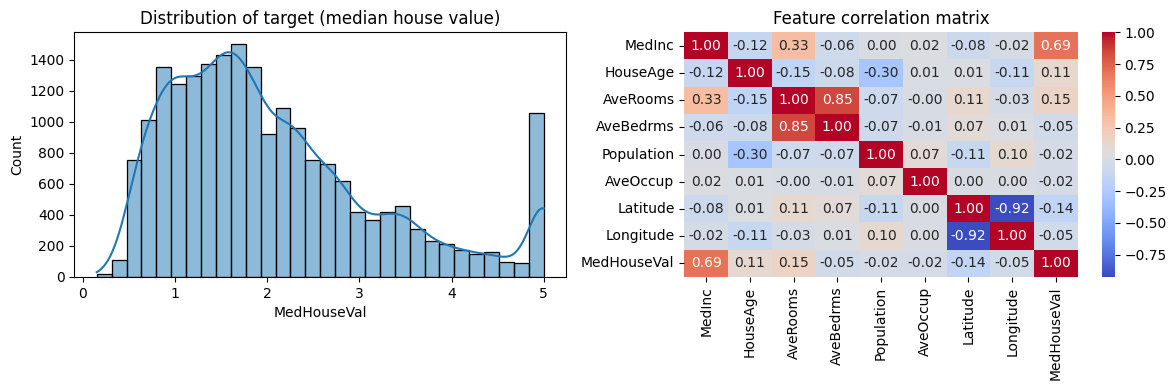


Top features correlated with target:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
Latitude       0.144160
HouseAge       0.105623
AveBedrms      0.046701
Longitude      0.045967
Population     0.024650
Name: MedHouseVal, dtype: float64


In [38]:
# Quick summary statistics
print('numeric columns summary:')
display(df.describe())

# show distribution of target
target_col = housing.target.name
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[target_col], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribution of target (median house value)')

# correlation heatmap
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Feature correlation matrix')
plt.tight_layout()
plt.show()

# show top correlations with the target
print('\nTop features correlated with target:')
print(corr[target_col].abs().sort_values(ascending=False).head(8))

## 3) Preprocessing: split + scaling

We'll split into train/test sets and standardize features for modeling.

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# prepare X and y
X = df.drop(columns=[target_col])
y = df[target_col]

# simple sanity check
print('X shape:', X.shape, '| y shape:', y.shape)

# split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train size:', X_train.shape[0], 'Test size:', X_test.shape[0])

# scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# show scaled means and stds for train
print('Scaled train mean (per feature):', np.round(X_train_scaled.mean(axis=0), 3))
print('Scaled train std  (per feature):', np.round(X_train_scaled.std(axis=0), 3))

X shape: (20640, 8) | y shape: (20640,)
Train size: 16512 Test size: 4128
Scaled train mean (per feature): [-0. -0.  0. -0.  0.  0.  0.  0.]
Scaled train std  (per feature): [1. 1. 1. 1. 1. 1. 1. 1.]


## 4) Modeling: train and evaluate

Train a simple LinearRegression model and measure performance on the test set. We'll also print coefficients and a baseline comparison.

In [40]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# train linear regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# predict
y_pred = lr.predict(X_test_scaled)

# metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"LinearRegression — RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}")

# coefficients
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': lr.coef_
}).sort_values(by='coefficient', key=lambda s: s.abs(), ascending=False)

display(coef_df)

# quickly compare with a regularized Ridge model
ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_train_scaled, y_train)
ridge_pred = ridge.predict(X_test_scaled)
print('Ridge RMSE:', np.sqrt(mean_squared_error(y_test, ridge_pred)))

LinearRegression — RMSE: 0.7456, MAE: 0.5332, R2: 0.5758


,feature,coefficient
6,Latitude,-0.896929
7,Longitude,-0.869842
0,MedInc,0.854383
3,AveBedrms,0.339259
2,AveRooms,-0.294410
1,HouseAge,0.122546
5,AveOccup,-0.040829
4,Population,-0.002308


Ridge RMSE: 0.745556744281478


## 5) Evaluation & Visualization

Visualize predictions vs actual and residuals to inspect model performance and patterns.

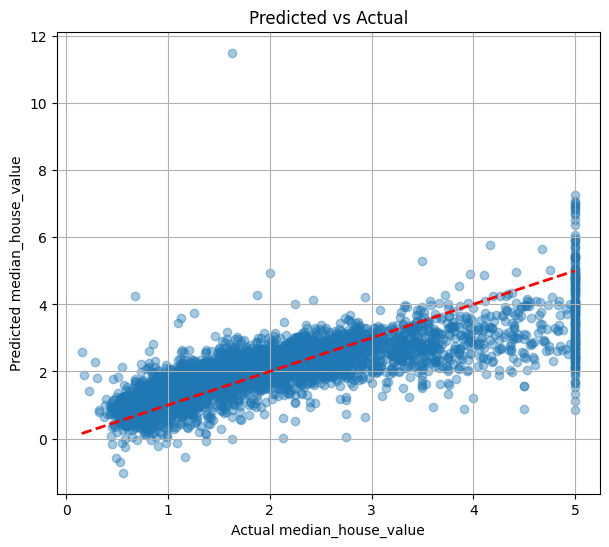

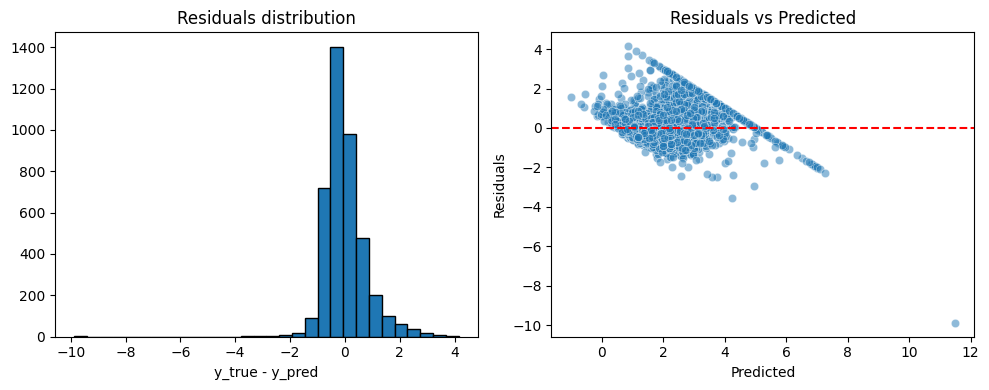

In [41]:
# predicted vs actual
plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel('Actual median_house_value')
plt.ylabel('Predicted median_house_value')
plt.title('Predicted vs Actual')
plt.grid(True)
plt.show()

# residuals
residuals = y_test - y_pred
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.hist(residuals, bins=30, edgecolor='k')
plt.title('Residuals distribution')
plt.xlabel('y_true - y_pred')

plt.subplot(1,2,2)
sns.scatterplot(x=y_pred, y=residuals, alpha=0.5)
plt.axhline(0, color='r', linestyle='--')
plt.title('Residuals vs Predicted')
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.tight_layout()
plt.show()

## 6) Save model and predictions

Store the trained model and the scaler with joblib and export predictions to a CSV for later analysis.

In [42]:
import joblib
from pathlib import Path

out_dir = Path('models')
out_dir.mkdir(parents=True, exist_ok=True)

model_path = out_dir / 'linear_regressor.joblib'
scaler_path = out_dir / 'scaler.joblib'

joblib.dump(lr, model_path)
joblib.dump(scaler, scaler_path)

print('Saved model to', model_path)
print('Saved scaler to', scaler_path)

# save predictions (join X_test for context)
pred_df = X_test.copy()
pred_df['y_true'] = y_test
pred_df['y_pred'] = y_pred
pred_df['residual'] = pred_df['y_true'] - pred_df['y_pred']

pred_file = out_dir / 'test_predictions.csv'
pred_df.to_csv(pred_file, index=False)
print('Saved test predictions to', pred_file)

Saved model to models/linear_regressor.joblib
Saved scaler to models/scaler.joblib
Saved test predictions to models/test_predictions.csv
